# 📄 Paper Review — DAFA: Distance-Aware Fair Adversarial Training
**Paper:** Lee et al., *DAFA: Distance-Aware Fair Adversarial Training*, ICLR 2024.

##  Overview
* **Domain:** Adversarial Robustness in Deep Neural Networks.
* **Baseline Framework:** TRADES (Trade-off between Robustness and Accuracy).
* **Core Goal:** Improve the worst class's robustness under attacks (e.g., PGD) by targeting the *similar* classes that cause the disparity — without degrading overall average robustness.



## 1. Background

**Adversarial examples & adversarial training (AT).**

Neural networks can be fooled by tiny, human-invisible noise added to input images. **Adversarial training** defends against this by training the model on such perturbed examples. **TRADES** is a popular AT method that balances clean accuracy and robustness by combining a cross-entropy loss on clean data with a KL-divergence term computed on adversarial examples.

**Robust fairness problem.**

Even with a balanced dataset, class-wise accuracy is not equal — some classes are "easy" and some are "hard". AT amplifies this gap: with TRADES on CIFAR-10, average robust accuracy is 49.8%, but the worst class reaches only 21.3%.

**Prior work.**

Existing fixes (FRL, CFA, BAT, WAT) borrow ideas from long-tailed classification: they restrict the learning of easy classes to boost hard ones — usually sacrificing average accuracy in return.

## 2. Problem

Adversarial training amplifies the accuracy gap between easy and hard classes the "robust fairness problem". A TRADES model on CIFAR-10, for example, reaches 49.8% average robust accuracy but only 21.3% on its worst class. Prior methods (FRL, CFA, BAT, WAT) treat this like a long-tailed problem: they restrict the learning of easy classes to boost hard ones, which improves the worst class only at the cost of average accuracy. This paper adds a missing piece to the picture: under adversarial attacks, most misclassified samples of the worst class are predicted as similar classes (cat → dog/deer), not easy ones (cat → ship/truck). Theory and experiments agree on the cause: the error gap grows as classes get closer in distance, so a class's difficulty comes from its similar neighbors, not from the class itself. The goal is to improve worst-class robust accuracy without sacrificing average accuracy، by targeting the similar classes that actually cause the gap.

**The key contrast:** the *same* cat data collapses to ~33% when trained alongside similar animal classes, but rockets to ~76% with dissimilar vehicle classes. The class itself didn't change — only its neighbors did. This is direct evidence that class difficulty is driven by **inter-class similarity**.
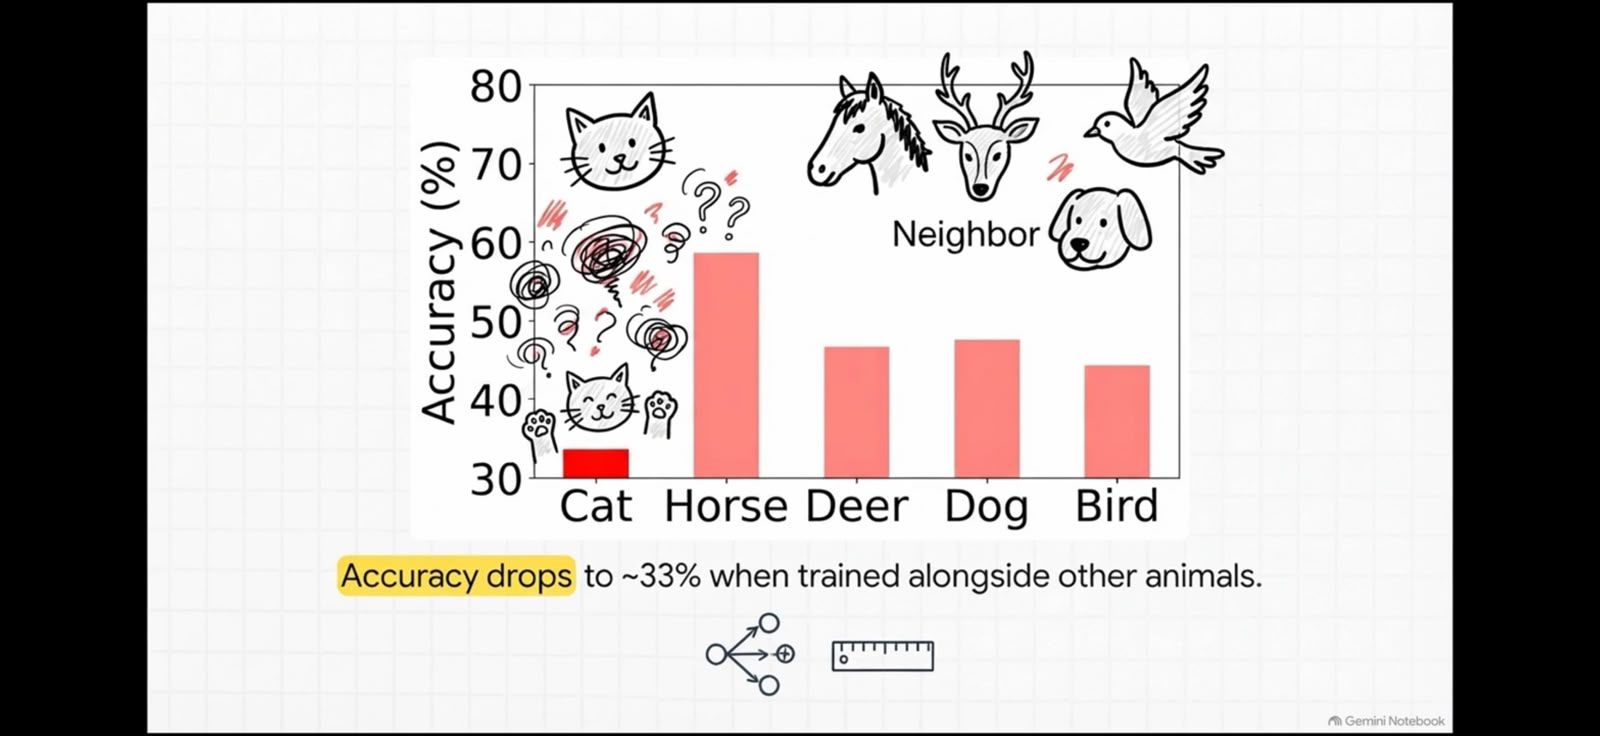
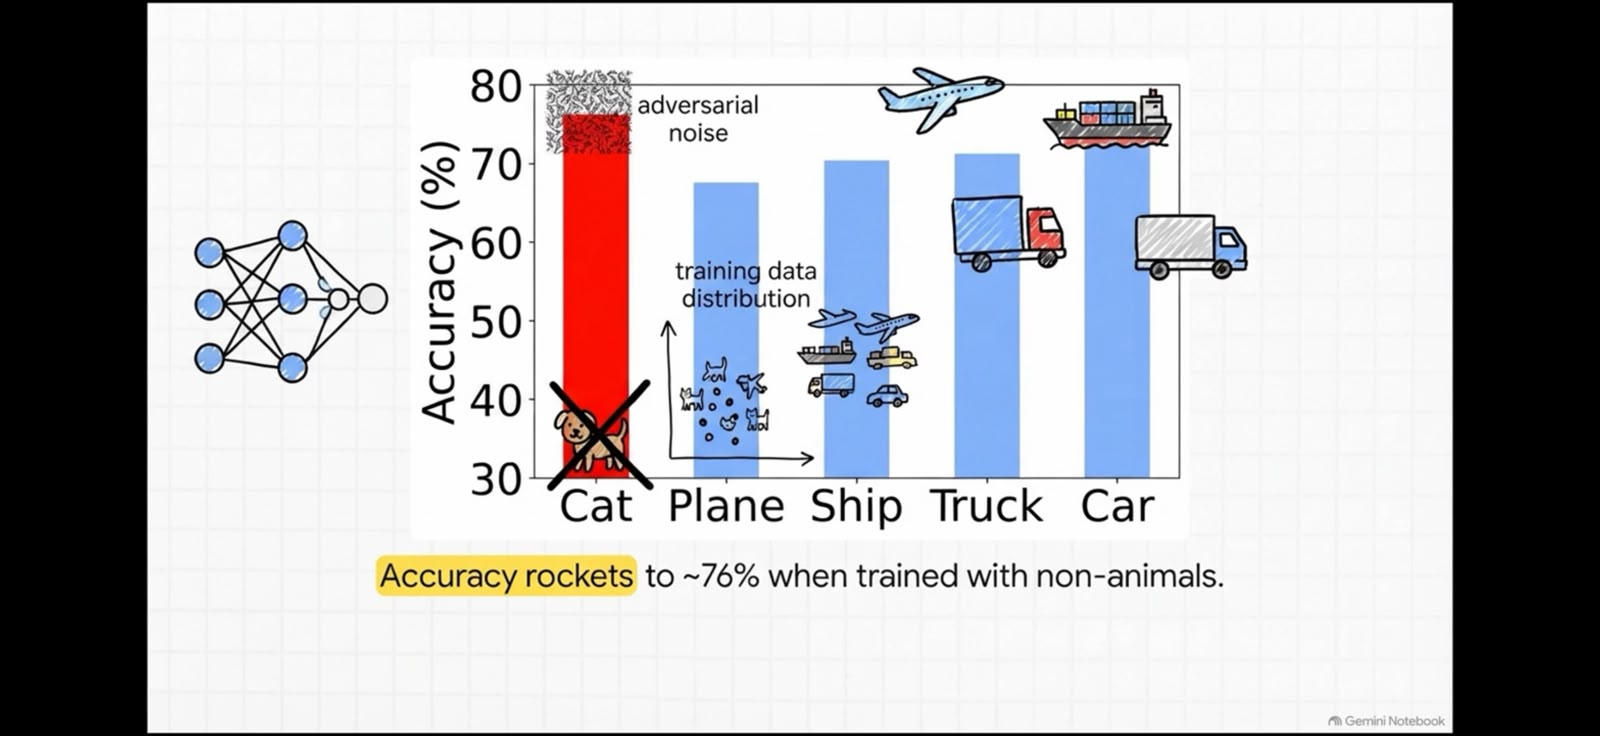

## 3.  Methodology  — DAFA

**Idea:** Shift the decision boundary between the hard class and its close classes using two per-class knobs in TRADES-style training:

- Class-wise loss weight $W_y$
- Class-wise adversarial margin $W_y \cdot \epsilon$

* **Step 1 — Measure Class Similarity:**

  Use the model's own outputs: the class-wise probability $p_i(j)$ represents the average softmax probability that data of class $i$ is predicted as class $j$. Similar classes get high $p_i(j)$, and $p_i(i)$ measures the difficulty of class $i$.


* **Step 2 — Redistribute Weight Between Class Pairs:**

  If class $i$ is harder than class $j$, weight is transferred from $j$ to $i$, scaled by their similarity:
  
  $$W_i = 1 + \lambda \sum_{j \neq i} \Big( \mathbb{1}[p_i(i) < p_j(j)]\; p_i(j)\,p_j(j) \;-\; \mathbb{1}[p_i(i) > p_j(j)]\; p_j(i)\,p_i(i) \Big)$$

  where $\lambda$ controls the scale of the shift.


* **Step 3 — Train with Distance-Aware Loss (TRADES Rewritten):**


  $$\mathcal{L}_{\text{DAFA}}(x, y) = W_y \cdot \mathrm{CE}(f(x), y) + \beta \max_{\|\delta\|_\infty \le W_y \epsilon} \mathrm{KL}\Big(f(x) \,\parallel\, f(x+\delta)\Big)$$



  Here $W_y$ scales both the clean loss (CE) and the adversarial budget ($W_y \cdot \epsilon$), so hard classes receive stronger training emphasis while average accuracy stays intact.




## 4. Results

The method was evaluated on CIFAR-10, CIFAR-100, and STL-10, using TRADES (ResNet18) as the baseline, the strong A³ attack for evaluation, and four competing fairness methods (FRL, CFA, BAT, WAT). Across all three datasets, DAFA achieves the best worst-class robust accuracy and the best fairness score (ρ), while keeping the average close to the baseline. The clearest example is CIFAR-10, where the worst class improves from 21.31% to 30.53% (+9.2 points) while the average barely changes (49.80% → 49.05%); the same pattern appears on CIFAR-100 (1.33% → 2.33%) and STL-10 (7.73% → 10.73%). Ablation studies show that both proposed components contribute: the loss weight alone lifts the worst class to 28.10%, the margin alone to 23.64%, and combining them reaches 30.53%. The improvement is also consistent across other architectures (PreActResNet18, WRN28) and training algorithms (PGD, AWP), indicating that the idea generalizes beyond a single setup.



## 5. Limitations

**Algorithm-dependence.**  On multi-class PGD(no clean data during training), the margin component DAFA_ε actually hurts worst robust accuracy (Table 6); it only works after adding AVmixup — so "larger ε for hard classes" is not universal.

**Warm-up dependency & static weights.** Requires ~70 warm-up epochs, and weights are computed once and frozen; if the model's class structure changes later in training, the weights become stale.

**Hyperparameter sensitivity.**  λ must be tuned per dataset (1.0 vs 1.5), and weight clipping is needed to keep W > 0 — extra tuning burden.
Small gains in very hard settings. On CIFAR-100, worst robust accuracy stays extremely low (1.33 → 2.33); fairness improves relatively, but the problem is far from solved.

**Scale not tested.** Only small benchmarks (CIFAR/STL); behavior on large-scale datasets or many-class settings is unclear, and there is a slight drop in average robust/clean accuracy.

# Distance-Aware Fair Adversarial Training (DAFA): A Practical Implementation on CIFAR-10

**Idea:** In adversarial training, the more difficult class (e.g., cat) is influenced by its similar classes (e.g., dog). DAFA assigns each class a weight (loss weight + ε) based on the similarity between the classes.

**Setup:** CIFAR-10 · ResNet18 · TRADES · 20 epochs (warm-up = 12)

In [18]:
import torch, torch.nn as nn, torch.nn.functional as F, numpy as np, pandas as pd, copy
import torchvision, torchvision.transforms as T, matplotlib.pyplot as plt
dev = 'cuda'
EPOCHS, WARMUP = 20, 12            # 20 epochs, DAFA starts after epoch 12
EPS, BETA, LAM = 8/255, 6.0, 1.0   # epsilon, TRADES beta, DAFA lambda

train = torchvision.datasets.CIFAR10('data', True, T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor()]), download=True)
test  = torchvision.datasets.CIFAR10('data', False, T.ToTensor(), download=True)
trl = torch.utils.data.DataLoader(train, 128, shuffle=True, num_workers=2)
tel = torch.utils.data.DataLoader(test, 256, num_workers=2)
classes = train.classes

def make_model():
    m = torchvision.models.resnet18(num_classes=10)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False); m.maxpool = nn.Identity()
    return m.to(dev)

## Dataset samples
One image from each class. Note the similarity between cat, dog, and deer.

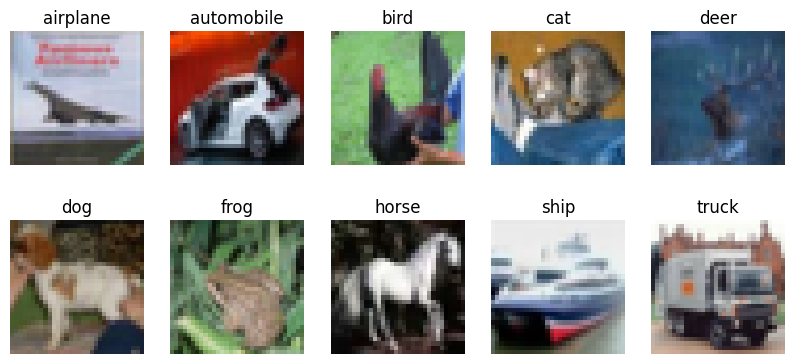

In [19]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for c, a in enumerate(ax.flat):
    a.imshow(test[test.targets.index(c)][0].permute(1, 2, 0)); a.set_title(classes[c]); a.axis('off')
plt.show()

## 1. Class weights (Eq. 8)
`P[i][j]` = Average probability that class i will be classified as j. The more difficult class takes a larger weight, and the easier, similar classes take a smaller weight.

In [20]:
def dafa_weights(P, lam=1.0, K=0.1):
    C = len(P); W = np.ones(C)
    for i in range(C):
        for j in range(C):
            if i == j: continue
            if P[i,i] < P[j,j]: W[i] += lam * P[i,j] * P[j,j]   # i أصعب
            elif P[i,i] > P[j,j]: W[i] -= lam * P[j,i] * P[i,i] # i أسهل
    return np.maximum(W, K)

## 2. Loss (Eq. 9)
Same as TRADES, but the weight `W` is multiplied by the CE and ε for each class. If `W = 1`, it returns to normal TRADES.

In [21]:
def dafa_trades_loss(model, x, y, W):
    w = torch.tensor(W, dtype=torch.float32, device=dev)[y]
    e = (w * EPS).view(-1,1,1,1)                      # ε لكل عينة
    model.eval()
    p_nat = F.softmax(model(x), 1).detach()
    x_adv = x + 0.001 * torch.randn_like(x)
    for _ in range(10):                               # attack (10 steps)
        x_adv.requires_grad_(True)
        kl = F.kl_div(F.log_softmax(model(x_adv), 1), p_nat, reduction='sum')
        g, = torch.autograd.grad(kl, x_adv)
        x_adv = torch.min(torch.max(x_adv.detach() + e/4 * g.sign(), x - e), x + e).clamp(0, 1)
    model.train()
    logits = model(x)
    ce = (w * F.cross_entropy(logits, y, reduction='none')).mean()
    kl = F.kl_div(F.log_softmax(model(x_adv), 1), F.softmax(logits, 1), reduction='batchmean')
    return ce + BETA * kl, x_adv.detach()

## 3. Training & evaluation
Evaluation is PGD-20 

In [22]:



def run(model, opt, W, start, end, collect=False):
    P, n = torch.zeros(10,10), torch.zeros(10)
    for ep in range(start, end):
        for g in opt.param_groups: g['lr'] = 0.05 * 0.1**((ep >= 16) + (ep >= 18))
        for i, (x, y) in enumerate(trl):
            x, y = x.to(dev), y.to(dev)
            loss, x_adv = dafa_trades_loss(model, x, y, W)
            if not torch.isfinite(loss): raise RuntimeError(f'nan at epoch {ep+1}, batch {i}')
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10)
            opt.step()
            if collect and ep == end - 1:
                model.eval()
                with torch.no_grad(): p = F.softmax(model(x_adv), 1).cpu()
                model.train()
                for c in range(10):
                    m = (y.cpu() == c); P[c] += p[m].sum(0); n[c] += m.sum()
        print(f'epoch {ep+1}/{EPOCHS} | loss {loss.item():.3f}')
    return (P / n[:, None]).numpy() if collect else None

def evaluate(model, steps=20):
    model.eval(); ok_c, tot = torch.zeros(10), torch.zeros(10)
    for x, y in tel:
        x, y = x.to(dev), y.to(dev)
        xa = (x + torch.empty_like(x).uniform_(-EPS, EPS)).clamp(0, 1)
        for _ in range(steps):
            xa.requires_grad_(True)
            g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
            xa = torch.min(torch.max(xa.detach() + EPS/4 * g.sign(), x - EPS), x + EPS).clamp(0, 1)
        with torch.no_grad(): ok = (model(xa).argmax(1) == y).cpu()
        for c in range(10):
            m = (y.cpu() == c); ok_c[c] += ok[m].sum(); tot[c] += m.sum()
    return (100 * ok_c / tot).numpy()


## 4) Execution / Run
1) Joint Warm-up (12 epochs) → 2) We calculate `W` → 3) We complete twice from the same checkpoint: TRADES and TRADES+DAFA.

In [23]:
model = make_model()
opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)

P = run(model, opt, np.ones(10), 0, WARMUP, collect=True)   # warm-up
W = dafa_weights(P, LAM)
ckpt = (copy.deepcopy(model.state_dict()), copy.deepcopy(opt.state_dict()))

results = {}
for name, w in [('TRADES', np.ones(10)), ('TRADES+DAFA', W)]:
    model.load_state_dict(ckpt[0]); opt.load_state_dict(ckpt[1])
    run(model, opt, w, WARMUP, EPOCHS)
    results[name] = evaluate(model)

epoch 1/20 | loss 1.790
epoch 2/20 | loss 1.788
epoch 3/20 | loss 1.782
epoch 4/20 | loss 1.661
epoch 5/20 | loss 1.674
epoch 6/20 | loss 1.656
epoch 7/20 | loss 1.597
epoch 8/20 | loss 1.523
epoch 9/20 | loss 1.476
epoch 10/20 | loss 1.530
epoch 11/20 | loss 1.532
epoch 12/20 | loss 1.411
epoch 13/20 | loss 1.469
epoch 14/20 | loss 1.539
epoch 15/20 | loss 1.465
epoch 16/20 | loss 1.449
epoch 17/20 | loss 1.364
epoch 18/20 | loss 1.338
epoch 19/20 | loss 1.281
epoch 20/20 | loss 1.248
epoch 13/20 | loss 1.289
epoch 14/20 | loss 1.397
epoch 15/20 | loss 1.621
epoch 16/20 | loss 1.497
epoch 17/20 | loss 1.348
epoch 18/20 | loss 1.323
epoch 19/20 | loss 1.281
epoch 20/20 | loss 1.375


## 5. Results

               TRADES  TRADES+DAFA
airplane    59.299999    58.700001
automobile  69.800003    60.000000
bird        27.500000    32.400002
cat         22.100000    29.200001
deer        27.900000    31.900000
dog         38.599998    33.700001
frog        51.599998    34.700001
horse       50.900002    48.299999
ship        65.699997    57.599998
truck       57.700001    65.599998

            TRADES  TRADES+DAFA
Average  47.110001    45.209999
Worst    22.100000    29.200001


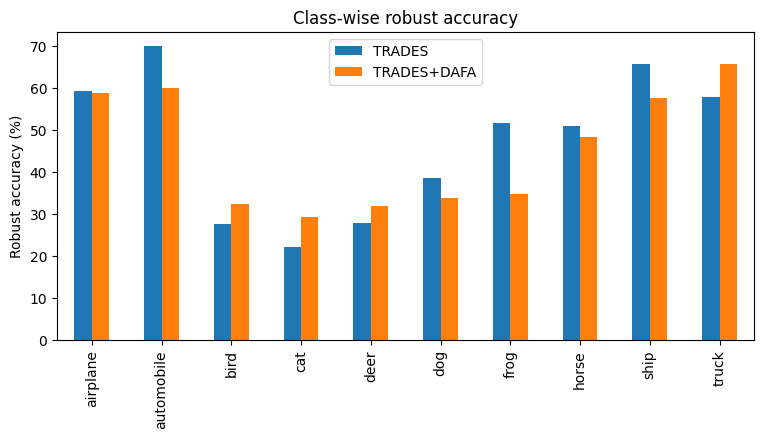

In [27]:
df = pd.DataFrame(results, index=classes)
summary = pd.DataFrame({'Average': df.mean(), 'Worst': df.min()}).T
print(df.round(1)); print(); print(summary.round(2))
df.plot.bar(figsize=(9,4)); plt.ylabel('Robust accuracy (%)'); plt.title('Class-wise robust accuracy'); plt.show()

## 6. Similarity & Weights Analysis
The map shows that the animal classes (cat, dog, bird...) are close, and the weights `W` give the difficult class a higher weight than its similar classes.

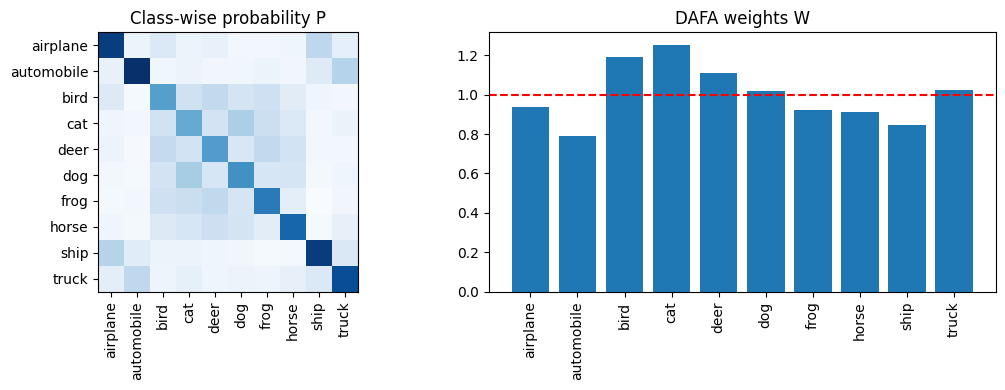

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].imshow(P, cmap='Blues'); ax[0].set_title('Class-wise probability P')
ax[0].set_xticks(range(10), classes, rotation=90); ax[0].set_yticks(range(10), classes)
ax[1].bar(classes, W); ax[1].axhline(1, color='r', ls='--'); ax[1].set_title('DAFA weights W')
ax[1].tick_params(axis='x', rotation=90); plt.tight_layout(); plt.show()

## Takeaway
- DAFA improves the worst robust accuracy while keeping the average close to TRADES.

- The results here are based on only 20 epochs, which is less than the Paper figures (110 epochs), but the trend is the same.